In [41]:
#imports
from aotools.turbulence import infinitephasescreen
from matplotlib import pyplot as plt
import numpy as np
from aotools import zernike
import pandas as pd
%matplotlib inline

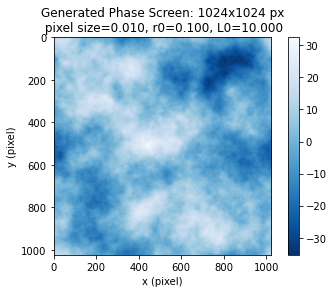

<Figure size 432x288 with 0 Axes>

In [42]:
#inputs
#n:   0 1 2 3  4  5  6   7   8   9   10   11   12   13    14    15    16
#2^n: 1 2 4 8 16 32 64 128 256 512 1024 2048 4096 8192 16384 32768 65536
scrn_size=1024
pixel_scale=0.01
r0=0.1
L0=10
radialDegree=15
#suggested zernike<scrn_size*pixel_scale/2r0
#radialDegree    1   2   3    4   5   6   7   8   9  10  11  12  13  14  15  16  17  18  19  20  21  22  23  24
#zernike(approx) 1   3   6   10  15  21  28  36  45  55  66  78  91 105 120 136 153 171 190 210 231 253 276 300

#what should this class be able to do
#1 generate phase screen
#2 plot phase screen
#3 find zernike coeff
#4 plot zernike coeff
#5 plot fit phase

color_map = plt.cm.get_cmap('Blues')
reversed_color_map = color_map.reversed()

Nzernike=int(radialDegree*(radialDegree+1)/2)

phase_screen=infinitephasescreen.PhaseScreenVonKarman(scrn_size,pixel_scale,r0,L0)#number of pixel, pixel size, r0, L0
phase=phase_screen.scrn
plt.imshow(phase,cmap=reversed_color_map)
plt.xlabel('x (pixel)')
plt.ylabel('y (pixel)')
plt.title('Generated Phase Screen: {:d}x{:d} px\n pixel size={:.3f}, r0={:.3f}, L0={:.3f}'.format(scrn_size,scrn_size,pixel_scale,r0,L0))
plt.colorbar()
plt.show()
plt.clf()

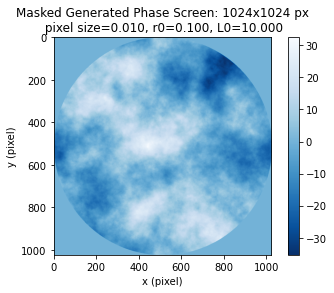

<Figure size 432x288 with 0 Axes>

In [43]:


x=np.arange(scrn_size)
x=x-scrn_size/2
xx,yy=np.meshgrid(x,x)
r=np.sqrt(xx**2+yy**2)
mask=np.zeros(r.shape)
for i in range(r.shape[0]):
    for j in range(r.shape[1]):
        if r[i,j]<=scrn_size/2:
            mask[i,j]=1
        else:
            mask[i,j]=0
            

plt.imshow(mask*phase,cmap=reversed_color_map)
plt.xlabel('x (pixel)')
plt.ylabel('y (pixel)')
plt.title('Masked Generated Phase Screen: {:d}x{:d} px\n pixel size={:.3f}, r0={:.3f}, L0={:.3f}'.format(scrn_size,scrn_size,pixel_scale,r0,L0))
plt.colorbar()
plt.show()
plt.clf()

In [44]:
modes=zernike.zernikeArray(Nzernike,scrn_size)
#for i in range(len(modes)):
#    plt.imshow(modes[i],cmap='inferno')
#    plt.xlabel('x (pixel)')
#    plt.ylabel('y (pixel)')
#    plt.title('Zernike Mode #{:d}'.format(i))
#    plt.colorbar()
#    plt.show()
#    plt.clf()
    

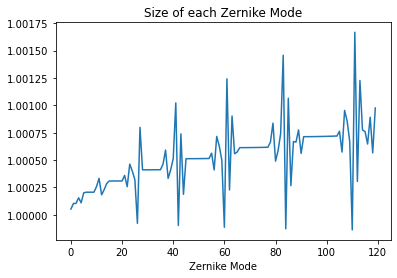

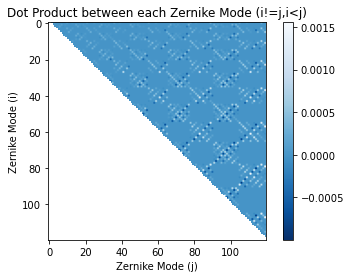

<Figure size 432x288 with 0 Axes>

In [45]:
normality_check=np.zeros(Nzernike)
zeromode=modes[0].sum()
for i in range(Nzernike):
    normality_check[i]=(modes[i]**2).sum()/(np.pi*((scrn_size/2)**2))

plt.plot(normality_check)
plt.xlabel('Zernike Mode')
plt.title('Size of each Zernike Mode')
plt.show()
plt.clf()

#print(normality_check)

orthogonality_check=np.empty((Nzernike,Nzernike))
orthogonality_check[:,:]=np.NaN
for i in range(Nzernike):
    for j in range(Nzernike):
        if i!=j:
            if i<j:
                orthogonality_check[i,j]=(modes[i]*modes[j]).sum()/((np.pi*(scrn_size/2)**2)*normality_check[i]*normality_check[j])
        
plt.imshow(orthogonality_check,cmap=reversed_color_map)
plt.xlabel('Zernike Mode (j)')
plt.ylabel('Zernike Mode (i)')
plt.title('Dot Product between each Zernike Mode (i!=j,i<j)')
plt.colorbar()
plt.show()
plt.clf()

#pd.DataFrame(orthogonality_check)

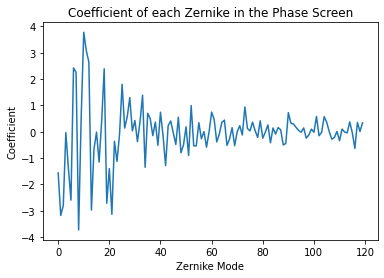

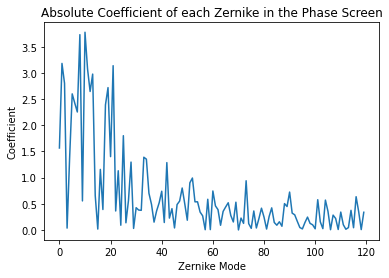

<Figure size 432x288 with 0 Axes>

In [46]:
phase_screen=infinitephasescreen.PhaseScreenVonKarman(scrn_size,pixel_scale,r0,L0)#number of pixel, pixel size, r0, L0
phase=phase_screen.scrn

coeff=np.zeros(Nzernike)
for i in range(Nzernike):
    coeff[i]=(mask*phase*modes[i]).sum()/(normality_check[i]*(np.pi*(scrn_size/2)**2))
    
pd.DataFrame(coeff)
plt.plot(coeff)
plt.title('Coefficient of each Zernike in the Phase Screen')
plt.xlabel('Zernike Mode')
plt.ylabel('Coefficient')
plt.show()
plt.clf()

plt.plot(np.sqrt(coeff**2))
plt.title('Absolute Coefficient of each Zernike in the Phase Screen')
plt.xlabel('Zernike Mode')
plt.ylabel('Coefficient')
plt.show()
plt.clf()

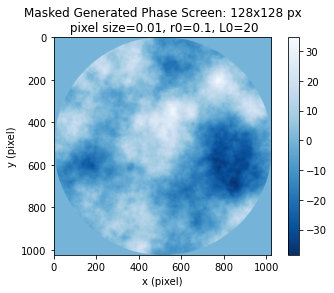

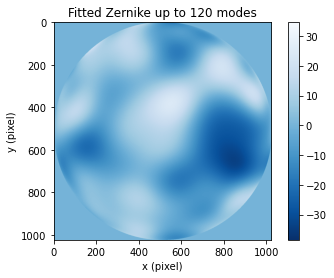

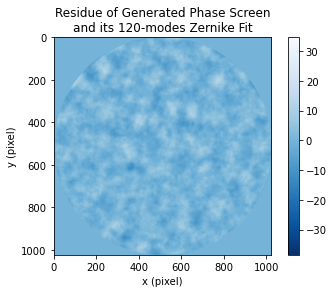

observe rms=
10.994591485362951
fit rms=
10.649931501777258
residue rms=
2.7200970509422007


<Figure size 432x288 with 0 Axes>

In [47]:
observe=mask*phase
calculate=zernike.phaseFromZernikes(coeff,scrn_size)
residue=observe-calculate

mapmax=observe.max()
mapmin=observe.min()

plt.imshow(observe,cmap=reversed_color_map,vmin=mapmin,vmax=mapmax)
plt.xlabel('x (pixel)')
plt.ylabel('y (pixel)')
plt.title('Masked Generated Phase Screen: 128x128 px\n pixel size=0.01, r0=0.1, L0=20')
plt.colorbar()
plt.savefig('PhaseScreen')
plt.show()
plt.clf()

plt.imshow(calculate,cmap=reversed_color_map,vmin=mapmin,vmax=mapmax)
plt.colorbar()
plt.title('Fitted Zernike up to {:d} modes'.format(Nzernike))
plt.xlabel('x (pixel)')
plt.ylabel('y (pixel)')
plt.savefig('FittedZernike')
plt.show()
plt.clf()


plt.imshow(residue,cmap=reversed_color_map,vmin=mapmin,vmax=mapmax)
plt.colorbar()
plt.title('Residue of Generated Phase Screen\nand its {:d}-modes Zernike Fit'.format(Nzernike))
plt.xlabel('x (pixel)')
plt.ylabel('y (pixel)')
plt.savefig('Residue')
plt.show()
plt.clf()

### this rms include the out of pupil for calculation too, which is bad. ##
print('observe rms=')
print(observe.std())
print('fit rms=')
print(calculate.std())
print('residue rms=')
print(residue.std())

In [48]:
#pd.DataFrame(phase)